In [2]:
# ==================================
# IMPORTS
# ==================================

from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parents[2].resolve()

sys.path.insert(
    0,
    str(PROJECT_ROOT)
)


import torch
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, Image, Video
from IPython.display import HTML

from torch.utils.data import DataLoader, random_split

from FNO.Navier.cavity_driven.solver import solve_cavity_driven
from FNO.Navier.cavity_driven.dataset import CavityDrivenDataset
# from FNO.Navier.core.fno import FNO1d
# import numpy as np

Using: mps
dt = 0.001
nt = 1000
Step=0 CFL=0.0630
Step=100 CFL=0.0630
Step=200 CFL=0.0630
Step=300 CFL=0.0630
Step=400 CFL=0.0630
Step=500 CFL=0.0630
Step=600 CFL=0.0630
Step=700 CFL=0.0630
Step=800 CFL=0.0630
Step=900 CFL=0.0630
51
torch.Size([64, 64])


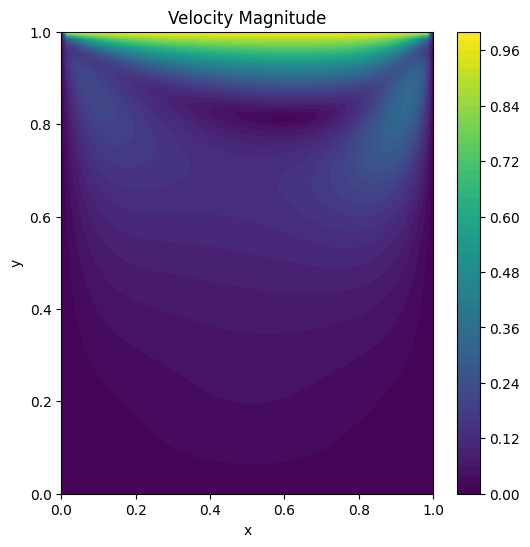

In [2]:
u_hist, v_hist, p_hist, x, y = solve_cavity_driven(verbose= True)

print(len(u_hist))

print(u_hist[-1].shape)

speed = torch.sqrt(
u_hist[-1]**2 +
v_hist[-1]**2
)
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))

plt.contourf(
    x,
    y,
    speed,
    levels=50
)

plt.colorbar()

plt.xlabel("x")
plt.ylabel("y")

plt.title("Velocity Magnitude")
plt.show()

    

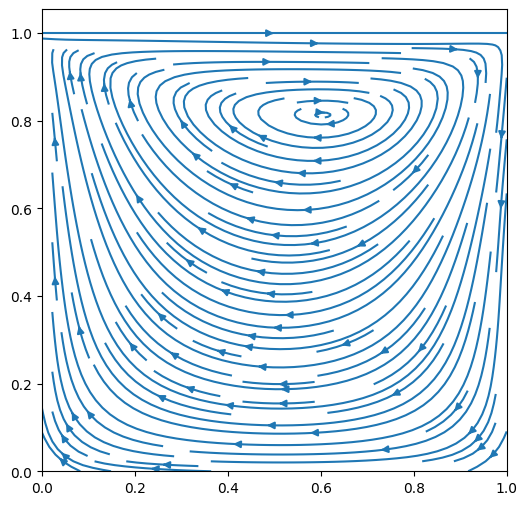

In [3]:
X, Y = torch.meshgrid(
x,
y,
indexing="xy"
)

plt.figure(figsize=(6,6))

plt.streamplot(
    X.numpy(),
    Y.numpy(),
    u_hist[-1].numpy(),
    v_hist[-1].numpy(),
    density=1.5
)

plt.show()


In [15]:
u_hist, v_hist, p_hist, x, y = solve_cavity_driven(
    T_final=5.0,
    dt=0.001,
    nu=0.01,
    save_every=20,
    device= 'cpu'
)

print(f"Frames: {len(u_hist)}")

Frames: 251


In [5]:
speed_hist = []

for u, v in zip(u_hist, v_hist):

    speed = torch.sqrt(
        u**2 + v**2
    )

    speed_hist.append(
        speed.cpu()
    )

In [6]:
X, Y = torch.meshgrid(
    x,
    y,
    indexing="xy"
)

X = X.numpy()
Y = Y.numpy()

In [12]:
# figure setup
fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(12, 6)
)

fig.suptitle(
    "Lid Driven Cavity Flow",
    fontsize=16
)

# velocity magnnitude plot
im = ax1.imshow(
    speed_hist[0],
    origin="lower",
    extent=[0, 1, 0, 1],
    animated=True
)

cbar = fig.colorbar(
    im,
    ax=ax1
)

ax1.set_title(
    "Velocity Magnitude"
)

ax1.set_xlabel("x")
ax1.set_ylabel("y")

# velocity field plot
skip = 3

Q = ax2.quiver(
    X[::skip, ::skip],
    Y[::skip, ::skip],
    u_hist[0].numpy()[::skip, ::skip],
    v_hist[0].numpy()[::skip, ::skip],
    angles='xy',
    scale_units='xy',
    scale=2
)

ax2.set_xlim(0,1)
ax2.set_ylim(0,1)

ax2.set_title(
    "Velocity Field"
)

ax2.set_xlabel("x")
ax2.set_ylabel("y")

# update function
def update(frame):

    # ------------------
    # Left Panel
    # ------------------

    im.set_array(
        speed_hist[frame]
    )

    ax1.set_title(
        f"Velocity Magnitude\nFrame {frame}"
    )

    # ------------------
    # Right Panel
    # ------------------

    Q.set_UVC(
        u_hist[frame].numpy()[::skip, ::skip],
        v_hist[frame].numpy()[::skip, ::skip]
    )

    ax2.set_title(
        f"Velocity Vectors\nFrame {frame}"
    )

    return (
        im,
        Q
    )

# animate
ani = FuncAnimation(
    fig,
    update,
    frames=len(u_hist),
    # frames= 50,
    interval=50,
    blit=False
)

# # display
# HTML(
#     ani.to_jshtml()
# )

# save
ani.save(
    "cavity_solver_demo.mp4",
    fps = 30,
    writer = "ffmpeg"
)

plt.close(fig)

In [13]:
# display
Video(
    "cavity_solver_demo.mp4",
    embed=True
)

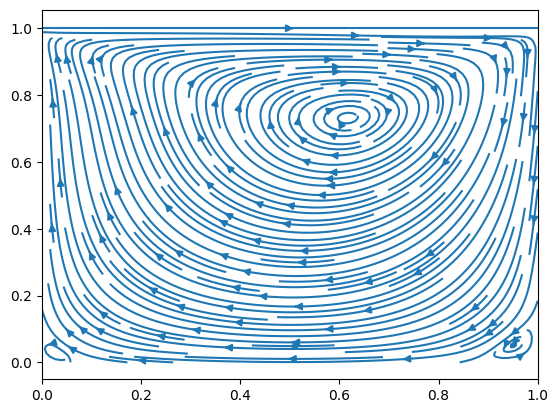

In [11]:
plt.streamplot(
    X,
    Y,
    u_hist[-1].numpy(),
    v_hist[-1].numpy(),
    density=2.0
)

In [18]:
dx = dy = x[1] - x[0]
u = u_hist[-1]
v = v_hist[-1]
div = (
    (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx)
    +
    (v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy)
)

In [19]:
print("Max divergence :", div.abs().max().item())
print("Mean divergence:", div.abs().mean().item())

Max divergence : 8.324359893798828
Mean divergence: 0.023021308705210686


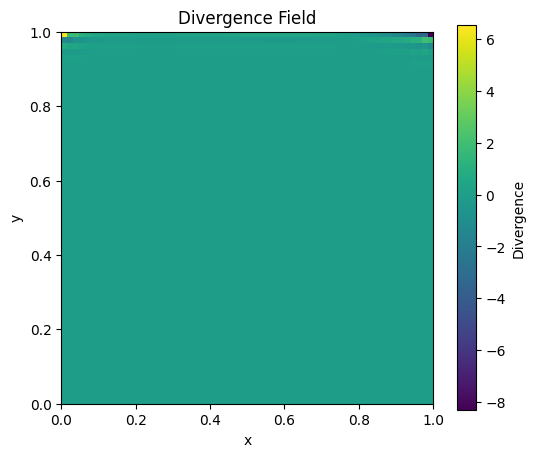

In [20]:
plt.figure(figsize=(6,5))

plt.imshow(
    div.numpy(),
    origin="lower",
    extent=[0,1,0,1]
)

plt.colorbar(label="Divergence")

plt.title("Divergence Field")
plt.xlabel("x")
plt.ylabel("y")

plt.show()

In [21]:
interior_div = div[5:-5, 5:-5]

print(
    "Interior Max:",
    interior_div.abs().max().item()
)

print(
    "Interior Mean:",
    interior_div.abs().mean().item()
)

Interior Max: 0.028367042541503906
Interior Mean: 0.00024193250283133239


In [24]:
dataset = CavityDrivenDataset(
    "data/cavity_dataset_20.pt"
)

sample = dataset[0]

print(sample["a"].shape)
print(sample["u"].shape)

torch.Size([5, 64, 64])
torch.Size([2, 64, 64])


In [25]:
print(len(dataset))
print(dataset[0]["a"].shape)
print(dataset[0]["u"].shape)

1000
torch.Size([5, 64, 64])
torch.Size([2, 64, 64])


Using: cpu


Text(0, 0.5, 'Mean Velocity')

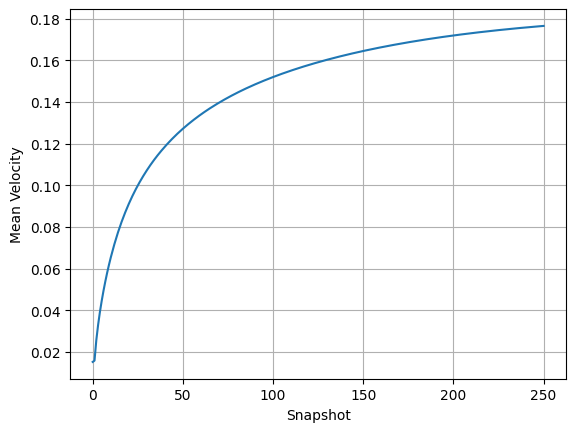

In [4]:
u_hist, v_hist, _, _, _ = solve_cavity_driven(
    nu=0.01,
    T_final=5.0,
    save_every=20,
    device= 'cpu'
)

u_hist = torch.stack(u_hist)
v_hist = torch.stack(v_hist)

energy = []

for u, v in zip(u_hist, v_hist):
    speed = torch.sqrt(u**2 + v**2)
    energy.append(speed.mean().item())

plt.plot(energy)
plt.grid()
plt.xlabel("Snapshot")
plt.ylabel("Mean Velocity")